> **中文阅读版**：本文件是 `06_finbert_cross_dataset.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 一个用含义不同的标签来评分的模型

**第 10 章：文本特征工程**
**章节参考**：第 10.4 节

**Docker 镜像**：`ml4t-gpu`

> **建议使用 GPU**：本 notebook 会在约八千条新闻标题上运行 FinBERT。GPU 端到端约需一分钟；CPU 则要数倍时间。要启用 GPU 加速：
> ```bash
> docker compose run --rm ml4t-gpu python 10_text_feature_engineering/06_finbert_cross_dataset.py
> ```

## 本 notebook 的用途

一个模型在自己的测试划分上得分很高，在别人的数据上表现很差，这是常见情况；真正有用的能力是诊断出这背后究竟是几种迥异原因中的哪一种。本 notebook 把一个案例完整走一遍。

将 `ProsusAI/finbert` 应用于 FinMarBa，这是一个金融新闻标题语料库。二者都带有三个名为 negative、neutral 和 positive 的标签，都是金融文本，而得到的准确率远低于模型在其自身领域报告的水平。最直观的解读是：该模型不具备迁移能力。

这种直观解读是错误的，而数据集在一个 notebook 加载后却忽略的列中已经说明了这一点。FinMarBa 的标签并不是对新闻标题的判断；它是所提及股票随后走势的符号。这两个语料库在三个标签*名称*上一致，却在标签*用途*上不一致。因此，这里的数字衡量的是情绪解读对价格变动的预判能力，这与模型能否在新领域读取情绪是不同的问题——而且是难得多的问题，将在 `07_news_return_signals` 中讨论。

## 学习目标

完成本 notebook 后，你将能够：

- 从标签的生成方式而非名称来理解数据集的标签定义，并判断两个共享标签名称的数据集是否共享同一任务。
- 在把准确率解读为能力之前，先将其与多数类比例进行比较。
- 区分跨数据集性能下降中常被混为一谈的三类原因：文本看起来不同、标注标准不同，或目标是不同的量。
- 说明当模型对类别的理解与数据不匹配时，混淆矩阵如何显示模型误差的偏向。

## 前置条件

- 本章第 10.4 节。
- 一个能够获取 `baptle/financial_headlines_market_based` 的 Hugging Face `datasets` 缓存；该数据集在首次运行时下载。

## 相关 notebook

- `04_bert_finetuning.py`——在其自身领域上微调同一检查点
- `07_news_return_signals.py`——衡量新闻情绪相对于收益的价值

In [1]:
"""Score FinBERT against market-derived labels and diagnose what the gap measures."""

import os

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from transformers import pipeline

from utils.paths import get_chapter_dir
from utils.reproducibility import set_global_seeds
from utils.style import COLORS, FIGSIZE, show_with_alt

# The tokenizer's Rust parallelism forks after this process has already used threads, which
# it warns about on every batch. One inference pass over eight thousand short headlines does
# not need it.
os.environ["TOKENIZERS_PARALLELISM"] = "false"

In [2]:
SEED = 42
SAMPLE_SIZE = 10000

In [3]:
# Reproducibility - set_global_seeds covers Python random / NumPy / Torch.
set_global_seeds(SEED)

device = 0 if torch.cuda.is_available() else -1
print(f"Using device: {'GPU' if device == 0 else 'CPU'}")

Using device: GPU


## 语料库及其标签来源

FinMarBa 将金融新闻标题与每条标题提及的股票随后的百分比变动配对。其 `Global Sentiment` 列——本 notebook 将其用作标签——是这些变动跨股票聚合后的符号；因此，只要标题提及的标的上涨，无论标题说了什么，这条标题就是“positive”。

这与 Financial PhraseBank 的标注标准不同：在后者中，标注者阅读每个句子并判断其表达的内容。二者都产生三个名称相同的类别。但只有其中一个是关于文本本身的陈述。

上游数据集自首次发布以来已调整过规模，因此加载器最多请求 `SAMPLE_SIZE` 行，并取实际可用的数据。

In [4]:
def load_finmarba_dataset(sample_size: int = 10000) -> pl.DataFrame:
    """Load FinMarBa dataset from Hugging Face.

    Args:
        sample_size: Number of samples to use (dataset has 60K+ samples).
            Set to 0 for all samples.

    Raises:
        RuntimeError: If dataset cannot be loaded (network error, etc.)
    """
    try:
        # Try 'test' split first, fall back to 'train' (dataset structure changed)
        try:
            ds = load_dataset(
                "baptle/financial_headlines_market_based",
                split="test",
            )
            print("Loaded FinMarBa test split")
        except ValueError:
            # Dataset may only have 'train' split now
            split_str = f"train[:{sample_size}]" if sample_size > 0 else "train"
            ds = load_dataset(
                "baptle/financial_headlines_market_based",
                split=split_str,
            )
            print(f"Loaded FinMarBa train split (sampled {sample_size:,} samples)")

        df = pl.DataFrame(ds.to_pandas())

        # Handle schema changes: newer versions have different column names
        # Map 'Title' -> 'text' and 'Global Sentiment' -> 'label'
        if "Title" in df.columns and "text" not in df.columns:
            df = df.rename({"Title": "text"})
        if "Global Sentiment" in df.columns and "label" not in df.columns:
            # Global Sentiment is -1/0/1, map to 0/1/2 for consistency
            # -1 (negative) -> 0, 0 (neutral) -> 1, 1 (positive) -> 2
            df = df.with_columns((pl.col("Global Sentiment") + 1).cast(pl.Int64).alias("label"))

        print(f"Loaded FinMarBa dataset: {len(df):,} samples")
        return df
    except Exception as e:
        raise RuntimeError(
            f"\n"
            f"{'=' * 70}\n"
            f"DATASET NOT AVAILABLE: FinMarBa\n"
            f"{'=' * 70}\n"
            f"\n"
            f"Error: {e}\n"
            f"\n"
            f"This notebook requires the FinMarBa dataset from Hugging Face:\n"
            f"  baptle/financial_headlines_market_based\n"
            f"\n"
            f"Possible causes:\n"
            f"  - No internet connection\n"
            f"  - HuggingFace servers unavailable\n"
            f"  - Dataset has been moved or renamed\n"
            f"\n"
            f"To run this notebook, ensure you have internet access.\n"
            f"{'=' * 70}\n"
        ) from e


df = load_finmarba_dataset(sample_size=SAMPLE_SIZE)
LABEL_MAP = {0: "negative", 1: "neutral", 2: "positive"}

print("Label distribution:")
print(df.group_by("label").len().sort("label"))

majority_rate = df.group_by("label").len()["len"].max() / len(df)
print(f"Majority-class rate: {majority_rate:.1%}")

Loaded FinMarBa train split (sampled 10,000 samples)
Loaded FinMarBa dataset: 8,142 samples
Label distribution:
shape: (3, 2)
┌───────┬──────┐
│ label ┆ len  │
│ ---   ┆ ---  │
│ i64   ┆ u32  │
╞═══════╪══════╡
│ 0     ┆ 2477 │
│ 1     ┆ 2154 │
│ 2     ┆ 3511 │
└───────┴──────┘
Majority-class rate: 43.1%


多数类比例是下文每个准确率都必须对照解读的数字。一个忽略新闻标题、始终回答最常见标签的分类器就能得到该分数，因此它是本数据上能力的零点，而不是三个平衡类别会给出的 33%。

### 标签由什么构成

该数据集附带了每个标签所依据的变动。把几行数据与其标签并排打印出来，就是本 notebook 的全部论证，而这只需一个单元格。

In [5]:
if "Pct_Change" in df.columns:
    evidence = df.select(["text", "Pct_Change", "label"]).head(4)
    for row in evidence.iter_rows(named=True):
        print(f"{row['text'][:70]}")
        print(f"    moves: {row['Pct_Change']}")
        print(f"    label: {LABEL_MAP[row['label']]}\n")
else:
    print("This copy of the dataset does not carry Pct_Change; the label is still its sign.")

Global Stocks and Commodities Rally on First Trading Day of 2010
    moves: {'ACWI': 0.02057236532425244}
    label: positive

Dollar Slumps Amid Worldwide Manufacturing Improvement
    moves: {'UUP': -0.006932462151207686, 'ACWI': 0.020571943968350936}
    label: neutral

Oil Prices Surge Above $81 a Barrel Due to U.S. Cold Weather
    moves: {'CL=F': 0.027091752889911946}
    label: positive

S&P 500 Sees 1.6 Percent Increase, Hits 15-Month High
    moves: {'^GSPC': 0.01604341766668682}
    label: positive



如果第二行是关于美元下跌的那一行，请读一下：一条任何读者都会称为负面情绪的新闻标题，其标签来自两只走势相反的股票。该标签是对这些变动的算术运算；它并不构成关于句子的任何断言。

## 模型

`ProsusAI/finbert` 是一个在 Financial PhraseBank 上针对情绪任务微调过的 BERT。这里应用它时未做进一步训练，这正是比较干净的原因：它产生的一切都来自从标注者判断中学到的内容，并用价格变动来评估。

In [6]:
model_name = "ProsusAI/finbert"
print(f"Loading {model_name}...")

classifier = pipeline(
    "sentiment-analysis",
    model=model_name,
    tokenizer=model_name,
    device=device,
    truncation=True,
    max_length=512,
)

# ProsusAI/finbert label mapping (lowercase labels)
FINBERT_LABEL_MAP = {"negative": 0, "neutral": 1, "positive": 2}

Loading ProsusAI/finbert...


Device set to use cuda:0


In [7]:
def get_finbert_predictions(texts: list[str], batch_size: int = 32) -> np.ndarray:
    """Get predictions from FinBERT."""
    predictions = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        results = classifier(batch)
        for r in results:
            predictions.append(FINBERT_LABEL_MAP[r["label"]])
    return np.array(predictions)

## 4. 在 FinMarBa 上评估 FinBERT

In [8]:
# Get the text column (may be 'headline' or 'text' depending on dataset)
text_col = "headline" if "headline" in df.columns else "text"
texts = df[text_col].to_list()
true_labels = df["label"].to_numpy()

print(f"Running FinBERT on {len(texts)} samples...")
predictions = get_finbert_predictions(texts)

# Compute metrics
accuracy = accuracy_score(true_labels, predictions)
f1 = f1_score(true_labels, predictions, average="macro")

print(f"Accuracy: {accuracy:.1%}  (majority-class rate: {majority_rate:.1%})")
print(f"F1 (macro): {f1:.3f}")

Running FinBERT on 8142 samples...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Accuracy: 49.4%  (majority-class rate: 43.1%)
F1 (macro): 0.428


## 这个数字意味着什么，以及不意味着什么

准确率略高于多数类比例。已发表的该 checkpoint 在自身留出的 PhraseBank 划分上的数字要高得多；本 notebook 并未复现该测量，因此应将其视为文献中的背景，而不是 notebook 内的比较。

这样的下降可能意味着三种不同情况，而它们需要不同的应对：

1. **文本不同。** 新闻标题比模型训练所用分析师句子更短、更直白。这是真实原因，解决办法是更多来自新领域的训练数据。
2. **标注标准不同。** 两名标注者可能对什么算作中性存在分歧。这是真实原因，解决办法是共享标注指南或校准步骤。
3. **目标量不同。** 标签回答的完全是另一个问题，文本侧无论做多少适配都无法弥合差距，因为模型没有被要求回答它被构建来回答的问题。

第三种正是这里发生的情况，上方的 `Pct_Change` 列就是证据。一个完美读出每个标题情绪的模型，只要悲观标题出现在上涨行情之前，仍然会错。本 notebook 衡量的更接近新闻情绪对收益的预测价值，这正是 `07_news_return_signals` 的主题，而没有人会期望它很高。

In [9]:
print(f"FinMarBa, zero-shot: accuracy {accuracy:.1%}, macro F1 {f1:.3f}, n={len(true_labels)}")
print(f"Always answering the majority class: accuracy {majority_rate:.1%}")

FinMarBa, zero-shot: accuracy 49.4%, macro F1 0.428, n=8142
Always answering the majority class: accuracy 43.1%


矩阵说明了分歧的方向，而单一准确率无法做到这一点。行是标题发布后市场的实际走势，列是模型对其解读，因此每个非对角线单元格统计一种分歧，整个网格显示这些分歧是均匀分布还是集中在某些类别。

它无法说明它们为什么分歧。同样的计数可能来自一个不确定的模型，也可能来自一个回答不同问题的模型，而计数表中没有任何东西能区分这两者。在这里给出定论的是前面打印的标签定义，而不是这个图。

有一列值得仔细阅读，然后就此打住。模型预测中性的频率远低于标签使用中性的频率。这是关于中间类别适用频率的已观察分歧，而这些计数所能确立的仅此而已。

有多种原因可能造成这一点。模型可能在这类文本上校准不佳，在本应弃权时却选择一个极性。或者，两个“中性”可能根本不是同一类别——市场中性是小幅变动，而情绪中性是表达无观点的句子，二者在同一批标题上不必以相同频率出现。区分它们需要对这些标题进行情绪标注，而没有人做过这样的标注，因此 notebook 记录这种分歧，但不归因。

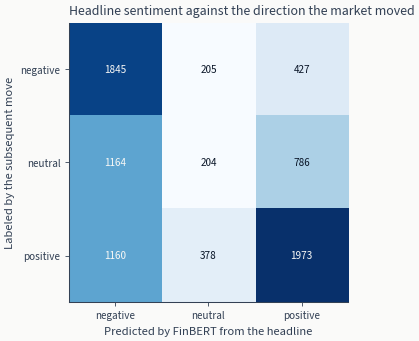

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE["single"])
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(true_labels, predictions)
ax.imshow(cm, cmap="Blues")

# Light text on the dark high-count cells; the threshold is half the largest count.
threshold = cm.max() / 2.0
for i in range(3):
    for j in range(3):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=8,
            color=COLORS["silver"] if cm[i, j] > threshold else COLORS["blue"],
        )

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.set_xlabel("Predicted by FinBERT from the headline")
ax.set_ylabel("Labeled by the subsequent move")
ax.set_title("Headline sentiment against the direction the market moved")

show_with_alt(
    fig,
    "A three-by-three grid of counts, with the label derived from the market move down the "
    "side and FinBERT's reading of the headline across the bottom. The counts are spread "
    "widely rather than concentrated on the diagonal, and each row puts substantial weight in "
    "more than one column. The middle column, where the model predicts neutral, is much "
    "lighter than the two beside it in all three rows, so the model rarely calls a headline "
    "neutral even on the row whose label says the market barely moved.",
)

## 关键要点

1. **从标签如何产生来理解其定义。** 两个数据集可以同意三个类别名称，却对类别的用途存在分歧。这里，一个由标注者阅读句子产生，另一个由取价格变动的符号产生，而产生它的列随数据一起提供。
2. **在称为能力之前，将准确率与多数类比例比较。** 在三个不平衡类别上，零点不是三分之一；而是始终回答最常见标签所能得到的分数。
3. **跨数据集下降至少有三类原因，且需要不同应对。** 不同文本、不同标注标准，或不同目标量。只有前两类可通过让模型适配新领域来解决；第三类意味着问题改变了，再多适配也不是答案。
4. **给原因命名会改变你接下来要做什么。** 若将其解读为领域偏移，这一结果支持在标题上做微调。若正确解读，它支持先决定你要的是文本在说什么的模型，还是价格接下来怎么走的模型，因为它们是不同的模型，而这里只训练了其中一个。
5. **混淆矩阵显示分歧在哪里，而不显示其原因。** 它值得一读，以了解哪些类别一致、哪些不一致，但它无法告诉你模型是不确定，还是在回答不同问题。只有标签的来源能说明这一点，而要衡量该模型的情绪表现，需要对这些标题进行情绪标注，而没有人做过。

In [11]:
output_dir = get_chapter_dir(10) / "output" / "finbert_cross_dataset"
output_dir.mkdir(parents=True, exist_ok=True)
results_file = output_dir / "results.md"
with open(results_file, "w") as f:
    f.write("# FinBERT scored against market-derived labels\n\n")
    f.write(f"- Headlines: {len(df):,}\n")
    f.write(f"- Accuracy: {accuracy:.1%}\n")
    f.write(f"- Macro F1: {f1:.3f}\n")
    f.write(f"- Majority-class rate: {majority_rate:.1%}\n\n")
    f.write("## What this measures\n\n")
    f.write(
        "FinMarBa's label is the sign of the subsequent move of the tickers a headline\n"
        "names, not a judgment about the headline. So this is the agreement between a\n"
        "sentiment reading and a price move, and not a measurement of how well the model\n"
        "reads sentiment in a new text domain.\n"
    )

# The path is printed relative to the repository so the render does not carry the absolute
# path of whichever checkout produced it.
print(f"Results saved to: {results_file.relative_to(get_chapter_dir(10).parent)}")

Results saved to: 10_text_feature_engineering/output/finbert_cross_dataset/results.md
